# Integrating ODEs: Euler, Runge-Kutta and Lyapunov Exponents

**Code:** [Open in Colab](https://colab.research.google.com/github/hy20577/complex-network-dynamics/blob/main/mkdoc_material/docs/tutorials/04_integrating_odes.ipynb) · [Download the notebook](https://hy20577.github.io/complex-network-dynamics/tutorials/04_integrating_odes/04_integrating_odes.ipynb) · [View on GitHub](https://github.com/hy20577/complex-network-dynamics/blob/main/mkdoc_material/docs/tutorials/04_integrating_odes.ipynb)

In the [previous guide](03_discrete_maps.ipynb) time advanced in steps. The continuous models
of the library (Lorenz, Rössler, Hindmarsh-Rose, Kuramoto) are systems of ordinary differential
equations (ODEs), which have to be solved numerically. In this guide we introduce the
numerical integration methods of the library, following Sections 3.1.1, 3.2.2 and 3.3.2 of the
[PhD thesis](https://repository.essex.ac.uk/39296/) [[1](#ref-1)], and use them on the Lorenz system of
[Yıldırım & Antonopoulos (2024)](https://doi.org/10.1016/j.chaos.2024.115554) [[2](#ref-2)].

You will learn:

1. how the Euler and the 4th-order Runge-Kutta (RK4) methods work, and how much their accuracy
   differs for the same step size;
2. how the Lyapunov exponents of a system of ODEs are computed together with its trajectory;
3. how an adaptive method (RK45) chooses its own step size;
4. how to simulate Lorenz systems coupled on a network, and which integrator of the library to
   choose.

In [1]:
try:
    import complex_network_dynamics as cnd
except ImportError:  # e.g. on Google Colab: install the library from GitHub
    %pip install -q git+https://github.com/hy20577/complex-network-dynamics.git
    import complex_network_dynamics as cnd

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(2)  # fixed seed, so the results are the same on every run

## 1. ODEs and Numerical Errors

Systems of ODEs are often challenging to solve analytically; therefore, numerical integration
methods are commonly used to calculate their trajectories [[3](#ref-3)]. The general form of an ordinary
differential equation is

$$
\dot{y} = f(t, y), \qquad y(t_{0}) = y_{0},
$$

where $\dot{y}$ is the time derivative of the variable $y$, $f(t, y)$ the function that defines
the system and $y_0$ the initial condition. Let the analytical solution of the system be $F_{t}$
and its numerical approximation $Y_{t}$ at time $t$. A numerical method advances the solution in
steps of size $h$, and makes two kinds of error:

- the **truncation error**, which comes from the method itself. The error made in one step is
  called the local truncation error, and the error accumulated up to time $t$, $E(t) = F_{t} -
  Y_{t}$, the global truncation error. Both become smaller as $h$ decreases;
- the **round-off error**, which arises because computers carry out every operation with finite
  precision. It grows with the number of steps, so a smaller $h$, which needs more steps, does not
  always give a more accurate result.

## 2. The Euler Method

The fundamental technique to approximate the solution of a system of ODEs is the Euler method.
It uses the Taylor series expansion of the solution,

$$
y(t + h) = y(t) + h\, \dot{y}(t) + \frac{h^{2}}{2!} \ddot{y}(t) + \frac{h^{3}}{3!} y^{(3)}(t) + \ldots,
$$

and keeps its first two terms only. Since $\dot{y} = f(t, y)$, this gives

$$
y_{n+1} = y_{n} + h f(t_n, y_{n}),
$$

where $h$ is the step size. The method follows the slope at the beginning of the step for the
whole step. The neglected terms start with $h^2$, so the local truncation error is of order
$h^2$ and the global one of order $h$: halving the step size only halves the error.

**Algorithm 1: Euler method**

1. Define $f(t, y)$ and set the initial values $t = t_0$, $y = y_0$.
2. Choose the step size $h$ and the number of steps $n$.
3. Repeat $n$ times:
    - $y \leftarrow y + h f(t, y)$,
    - $t \leftarrow t + h$.
4. Return $t$ and $y$.

In the library, this is `cnd.euler_with_lyapunov`. With `lyap_mode="none"` it returns the times
and the trajectory only; in Section 4, we also use it to compute Lyapunov exponents.

### Example: the Lotka-Volterra (Predator-Prey) Model

We test it on the Lotka-Volterra model, a 2-dimensional nonlinear system in which the populations
of a prey, $x$, and of a predator, $p$, oscillate over time,

$$
\begin{aligned}
\frac{dx}{dt} &= \alpha x - \beta x p, \\
\frac{dp}{dt} &= \delta x p - \gamma p,
\end{aligned}
$$

where

- $\alpha$ is the growth rate of the prey in the absence of predators,
- $\beta$ the predation rate,
- $\delta$ the growth rate of the predators per prey eaten,
- $\gamma$ the natural death rate of the predators.

In the library this is `cnd.lotka_volterra`, with the defaults $\alpha = 1.1$, $\beta = 0.4$,
$\delta = 0.1$ and $\gamma = 0.4$. This model is a good test because we know what the exact
solution looks like: the quantity

$$
V = \delta x - \gamma \ln x + \beta p - \alpha \ln p
$$

stays constant along every solution, so the trajectory in the $(x, p)$ plane is a closed curve
that repeats itself for ever. Any change of $V$ in a numerical solution is, therefore, an error
of the method.

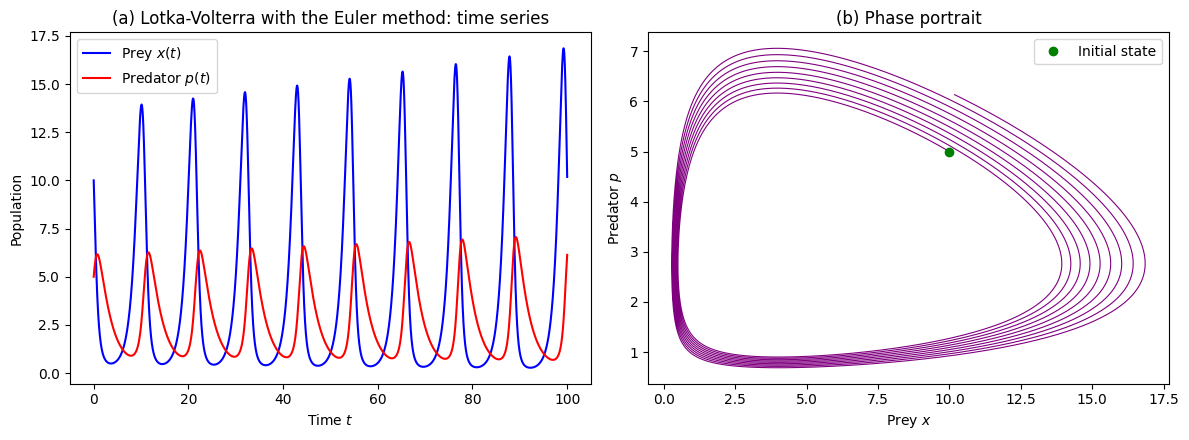

In [2]:
y0_lv = np.array([10.0, 5.0])  # 10 prey and 5 predators
h_lv = 0.01
n_steps_lv = 10_000            # total time = n_steps * h = 100

t_euler, lv_euler = cnd.euler_with_lyapunov(cnd.lotka_volterra, y0_lv, 0.0, h_lv, n_steps_lv + 1,
                                          lyap_mode="none", n_transient=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(t_euler, lv_euler[:, 0], "b-", label="Prey $x(t)$")
ax1.plot(t_euler, lv_euler[:, 1], "r-", label="Predator $p(t)$")
ax1.set_xlabel("Time $t$")
ax1.set_ylabel("Population")
ax1.set_title("(a) Lotka-Volterra with the Euler method: time series")
ax1.legend()

ax2.plot(lv_euler[:, 0], lv_euler[:, 1], color="purple", linewidth=0.8)
ax2.plot(*y0_lv, "go", label="Initial state")
ax2.set_xlabel("Prey $x$")
ax2.set_ylabel("Predator $p$")
ax2.set_title("(b) Phase portrait")
ax2.legend()
plt.tight_layout()
plt.show()

**Figure 1:** The Lotka-Volterra model integrated with the Euler method, with step size $h = 0.01$, from 10 prey and 5 predators up to $t = 100$. (a) The populations of the prey, $x(t)$ (blue), and of the predators, $p(t)$ (red), over time. (b) The same solution in the $(x, p)$ plane, where the green point marks the initial state.

The oscillations grow from one cycle to the next, and the curve in the phase portrait spirals
outwards instead of closing. This is not a property of the model but the truncation error of the
Euler method accumulating at every step. We quantify it with $V$ after introducing a better
method.

## 3. The 4th-Order Runge-Kutta Method (RK4)

The RK4 method is the most widely used member of the family of Runge-Kutta methods. Instead of
following the slope at the beginning of the step, it evaluates the slope at four points within
the step and combines them, so that the result agrees with the Taylor series expansion up to its
4th-order term:

$$
\begin{aligned}
k_1 &= f(t_n, y_n), \\
k_2 &= f\big(t_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2} k_1\big), \\
k_3 &= f\big(t_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2} k_2\big), \\
k_4 &= f(t_n + h,\ y_n + h k_3), \\
y_{n+1} &= y_n + \tfrac{h}{6}\,(k_1 + 2 k_2 + 2 k_3 + k_4).
\end{aligned}
$$

Its global truncation error is of order $h^4$: halving the step size makes the error 16 times
smaller, at the cost of four evaluations of $f$ per step instead of one.

In the library, RK4 is `cnd.rk4_with_lyapunov`, which takes the same arguments as
`cnd.euler_with_lyapunov`: the function `f`, the initial state `y0`, the initial time `t0`, the
step size `h` and the number of recorded points `n_steps`. With `lyap_mode="none"` they return
the times and the trajectory only. Below, we integrate the Lotka-Volterra model with RK4, using
the same step size as before, and compare the conserved quantity $V$ of the two solutions.

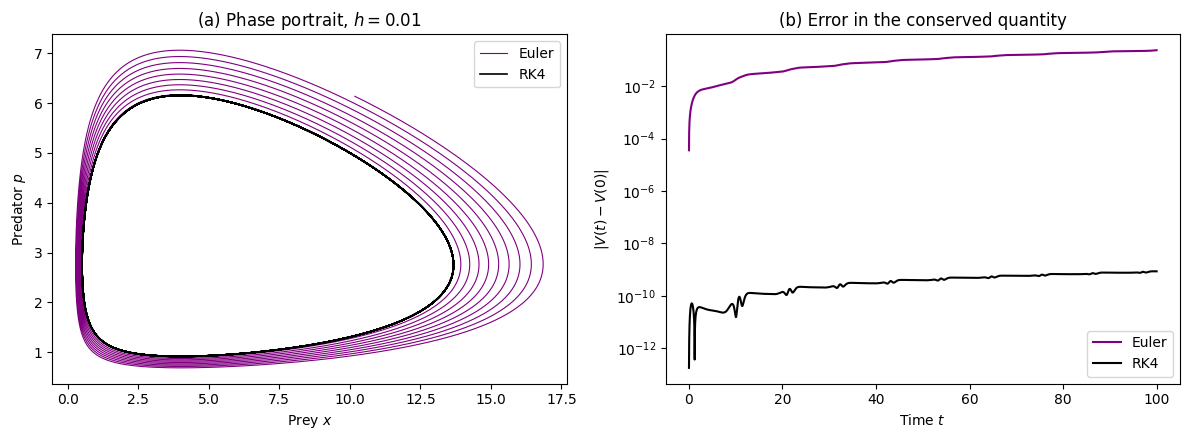

Error in V at t = 100:  Euler 2.40e-01,  RK4 8.56e-10


In [3]:
def conserved_quantity(y, alpha=1.1, beta=0.4, delta=0.1, gamma=0.4):
    x, p = y[:, 0], y[:, 1]
    return delta * x - gamma * np.log(x) + beta * p - alpha * np.log(p)


t_rk4, lv_rk4 = cnd.rk4_with_lyapunov(cnd.lotka_volterra, y0_lv, 0.0, h_lv, n_steps_lv + 1,
                                      lyap_mode="none", n_transient=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(lv_euler[:, 0], lv_euler[:, 1], color="purple", linewidth=0.8, label="Euler")
ax1.plot(lv_rk4[:, 0], lv_rk4[:, 1], color="black", linewidth=1.2, label="RK4")
ax1.set_xlabel("Prey $x$")
ax1.set_ylabel("Predator $p$")
ax1.set_title(f"(a) Phase portrait, $h = {h_lv}$")
ax1.legend()

V0 = conserved_quantity(y0_lv[None, :])[0]
ax2.semilogy(t_euler[1:], np.abs(conserved_quantity(lv_euler) - V0)[1:], color="purple", label="Euler")
ax2.semilogy(t_rk4[1:], np.abs(conserved_quantity(lv_rk4) - V0)[1:], color="black", label="RK4")
ax2.set_xlabel("Time $t$")
ax2.set_ylabel("$|V(t) - V(0)|$")
ax2.set_title("(b) Error in the conserved quantity")
ax2.legend()
plt.tight_layout()
plt.show()

print(f"Error in V at t = 100:  Euler {abs(conserved_quantity(lv_euler)[-1] - V0):.2e},  "
      f"RK4 {abs(conserved_quantity(lv_rk4)[-1] - V0):.2e}")

**Figure 2:** The Euler (purple) and RK4 (black) solutions of the Lotka-Volterra model of Fig. 1, both with $h = 0.01$. (a) The two solutions in the $(x, p)$ plane: the RK4 solution closes on itself, while the Euler solution spirals outwards. (b) The error in the conserved quantity, $|V(t) - V(0)|$, on a logarithmic scale.

With the same step size, the RK4 solution closes on itself and keeps $V$ constant many orders of
magnitude better than the Euler solution. To reach a similar accuracy, the Euler method would
need a far smaller step size, and, consequently, far more steps.

## 4. Lyapunov Exponents of a Flow

In the previous guide, the Lyapunov exponent of a map was the average of $\log|f'(x_n)|$
along the trajectory. For a system of ODEs the idea is the same (Section 3.2.2 of the thesis, following [[4](#ref-4), [5](#ref-5)]).
A small perturbation $\delta y$ of the solution evolves according to the **variational
equation**,

$$
\dot{J} = \Lambda(t)\, J, \qquad J(0) = I,
$$

where $\Lambda(t) = Df(y(t))$ is the Jacobian matrix of $f$ evaluated on the trajectory, and the
columns of $J$ are the perturbation vectors, which start as the unit vectors. Since $\Lambda(t)$
depends on the state at time $t$, the system and its variational equation have to be solved
simultaneously. The vectors are orthonormalised every few steps (the library uses a QR
decomposition, which is equivalent to the Gram-Schmidt process), so that they neither grow
without bound nor all collapse onto the most unstable direction. The Lyapunov exponents are the
averages of the logarithms of their growth per unit of time, $\lambda_1 \ge \lambda_2 \ge \dots
\ge \lambda_M$, one for each dimension of the system.

A bounded trajectory that is not periodic is chaotic if $\lambda_1 > 0$ [[6](#ref-6)]. Moreover, a trajectory of a system of ODEs
that does not end at a fixed point always has one exponent equal to zero, which corresponds to
a perturbation along the trajectory itself.

To see why, consider a perturbation that moves the initial state a little forward along its own
trajectory. The perturbed solution follows exactly the same path, only slightly ahead in time, so
the two solutions stay the same time apart for ever, like two cars on the same road, the second
starting one second after the first. The distance between them is not constant: it grows where
the motion speeds up and shrinks where it slows down. However, the speed stays bounded on the
attractor, so the distance neither grows nor decays exponentially, and its average growth rate,
the Lyapunov exponent, is zero. Note that this direction is not one of the axes of the phase
space: it is the direction of motion, which turns as the trajectory moves. A zero exponent,
therefore, does not mean that the trajectory never expands or shrinks in some direction, but that
along the direction of motion there is no exponential growth or decay on average. A map has no
such direction, since it jumps from one state to the next, which is why the coupled maps of the
previous guide have no zero exponent.

### The Sum of the Exponents and the Type of System

The exponents also tell us what happens to a small volume of initial conditions, rather than to a
single perturbation. Each exponent measures the stretching or shrinking along one direction, so
their sum measures how fast a small volume of the phase space grows or shrinks along the
trajectory, on average. This rate equals the average divergence of $f$, the sum of the diagonal
entries of its Jacobian matrix, which gives a simple check of a computed spectrum and sorts
systems into types:

- **Dissipative systems** (negative sum): volumes shrink, so trajectories are attracted to a set
  of lower dimension, such as a fixed point, a limit cycle or, if $\lambda_1 > 0$, a strange
  attractor. Systems with friction or damping, such as the Lorenz system below, are of this type.
  A positive exponent can coexist with a negative sum, because the stretching along one direction
  is outweighed by the contraction along the others.
- **Conservative systems** (zero sum): volumes are preserved on average, as in the mechanical
  systems without friction. They have no attractors, and every orbit keeps the value of a
  conserved quantity, as the closed orbits of the Lotka-Volterra model of Section 2 do; both of
  its exponents are zero.
- **Expanding systems** (positive sum): volumes grow, which is incompatible with an attractor; we
  do not meet such systems in these guides.

For a discrete map, the corresponding rate is the average of the logarithm of how much one
iteration stretches or shrinks a volume; for a single map, as in the previous guide, it is the
Lyapunov exponent itself.

### The Lorenz System

We use the system derived by Edward Lorenz as a model of convection in the atmosphere, whose
sensitivity to the initial conditions started what is now called chaos theory [[7](#ref-7)],

$$
\begin{aligned}
\dot{x} &= \sigma (y - x), \\
\dot{y} &= x (\rho - z) - y, \\
\dot{z} &= x y - \beta z,
\end{aligned}
$$

with $\sigma = 10$, $\rho = 28$ and $\beta = 8/3$, which lead to a chaotic orbit (Eq. (3.15) of
the thesis). In the library these are `cnd.lorenz` and its Jacobian matrix `cnd.lorenz_jacobian`.

To compute the Lyapunov exponents, we pass the Jacobian as `df`. The first `n_transient` steps
are discarded, so that the trajectory is on the attractor before the averaging starts, and the
vectors are orthonormalised every `qr_interval` steps. With `lyap_mode="history"` the functions
also return the running estimates of the exponents, which show how they converge.

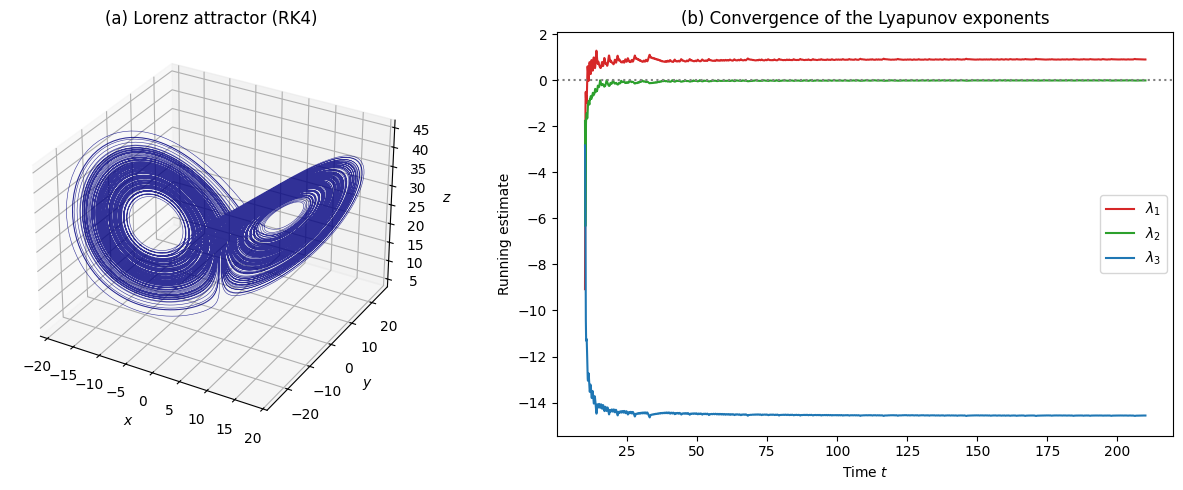

In [4]:
y0_lorenz = np.array([1.0, 1.0, 1.0])
h = 0.005
n_steps = 40_000      # recorded time = n_steps * h = 200
n_transient = 2_000   # the first 10 time units are discarded

t_lorenz, traj_lorenz, lyap_times, lyap_history = cnd.rk4_with_lyapunov(
    cnd.lorenz, y0_lorenz, 0.0, h, n_steps, df=cnd.lorenz_jacobian,
    lyap_mode="history", n_transient=n_transient, qr_interval=5,
)

fig = plt.figure(figsize=(13, 5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(*traj_lorenz.T, color="navy", linewidth=0.4, alpha=0.8)
ax1.set_xlabel("$x$")
ax1.set_ylabel("$y$")
ax1.set_zlabel("$z$")
ax1.set_title("(a) Lorenz attractor (RK4)")

ax2 = fig.add_subplot(1, 2, 2)
for k, colour in enumerate(["tab:red", "tab:green", "tab:blue"]):
    ax2.plot(lyap_times, lyap_history[:, k], color=colour, label=rf"$\lambda_{k + 1}$")
ax2.axhline(0, color="gray", linestyle=":")
ax2.set_xlabel("Time $t$")
ax2.set_ylabel("Running estimate")
ax2.set_title("(b) Convergence of the Lyapunov exponents")
ax2.legend(loc="center right")
plt.tight_layout()
plt.show()

**Figure 3:** The Lorenz system with $\sigma = 10$, $\rho = 28$ and $\beta = 8/3$, integrated with RK4 and $h = 0.005$ for 200 time units after a transient of 10. (a) The trajectory in the $(x, y, z)$ space, the Lorenz attractor. (b) The running estimates of the three Lyapunov exponents, $\lambda_1$ (red), $\lambda_2$ (green) and $\lambda_3$ (blue), over time; the dotted grey line marks zero.

The trajectory draws the butterfly-shaped Lorenz attractor, and the three exponents settle to
one positive, one zero and one negative value.

We now compare the two methods for the same step size, $h = 0.005$. There is an exact check of the
result: the sum of the exponents equals the average divergence of $f$,
which for the Lorenz system is the constant $-(\sigma + 1 + \beta) = -13.6667$.

In [5]:
rows = {}

for name, integrator in [("Euler", cnd.euler_with_lyapunov), ("RK4", cnd.rk4_with_lyapunov)]:
    _, _, spectrum = integrator(cnd.lorenz, y0_lorenz, 0.0, h, n_steps, df=cnd.lorenz_jacobian,
                                n_transient=n_transient, qr_interval=5)
    rows[f"{name}, h = {h}"] = spectrum

lorenz_table = pd.DataFrame(rows, index=["λ1", "λ2", "λ3"]).T
lorenz_table["Sum"] = lorenz_table.sum(axis=1)
lorenz_table.round(4)

,λ1,λ2,λ3,Sum
"Euler, h = 0.005",0.9428,0.0049,-14.7709,-13.8232
"RK4, h = 0.005",0.9027,-0.0067,-14.5626,-13.6667


Both methods give a chaotic orbit, but the Euler method misses the sum of the exponents in the
first decimal, while RK4 reproduces it. Note that the running estimates above still fluctuate after 200 time units, so a longer
trajectory is needed for more digits.

For the Lotka-Volterra model both exponents are zero, since its orbits are closed curves and
nearby orbits neither separate nor approach each other exponentially.

## 5. Adaptive Runge-Kutta Methods

The Euler and RK4 methods use the same step size everywhere, although a solution may change
quickly in some parts and slowly in others. Adaptive methods estimate the local truncation error
at every step by comparing two Runge-Kutta methods of orders $p$ and $p + 1$, and choose the
step size so that this error stays below a tolerance: small steps where the solution changes
quickly, large steps where it is smooth. The most common one is RK45, based on the
Dormand-Prince pair of orders 4 and 5 [[8](#ref-8)], which is the default of `scipy.integrate.solve_ivp` and
the method used for the continuous systems in the thesis and the paper.

In the library, `cnd.solve_ivp_with_lyapunov` wraps the SciPy solver. Since the Lyapunov
exponents and the later analysis need the solution at equally spaced times, the function
integrates over windows of length `dt_qr`; at the end of each window it records the state and
orthonormalises the perturbation vectors. Instead of a number of steps, it takes the total
time `t_total`, and the tolerances `rtol` and `atol`.

In [6]:
_, traj_rk45, spectrum_rk45 = cnd.solve_ivp_with_lyapunov(
    cnd.lorenz, y0_lorenz, 0.0, t_total=200, df=cnd.lorenz_jacobian,
    n_transient=200, dt_qr=0.05, method="RK45", rtol=1e-8, atol=1e-10,
)

lorenz_table.loc["RK45, rtol = 1e-8"] = [*spectrum_rk45, spectrum_rk45.sum()]
print("Shape of the RK45 trajectory, sampled every 0.05:", traj_rk45.shape)
lorenz_table.round(4)

Shape of the RK45 trajectory, sampled every 0.05: (4001, 3)


,λ1,λ2,λ3,Sum
"Euler, h = 0.005",0.9428,0.0049,-14.7709,-13.8232
"RK4, h = 0.005",0.9027,-0.0067,-14.5626,-13.6667
"RK45, rtol = 1e-8",0.9055,-0.0084,-14.5638,-13.6667


## 6. Coupled Lorenz Systems on a Network

To generate data from a network, we place one Lorenz system on every node and couple the nodes
through their $x$ variables (Eq. (20) of the paper, Eq. (3.16) of the thesis),

$$
\begin{aligned}
\dot{x}_i &= \sigma (y_i - x_i) + K \sum_{j=1}^{M} A_{ij} (x_j - x_i), \\
\dot{y}_i &= x_i (\rho - z_i) - y_i, \\
\dot{z}_i &= x_i y_i - \beta z_i,
\end{aligned}
$$

where $K$ is the coupling strength and $A$ the adjacency matrix of the $M$ nodes. In the library
this is `cnd.coupled_lorenz`, with the Jacobian matrix `cnd.coupled_lorenz_jacobian`. The state
is one vector of length $3M$, ordered as $[x_1, \dots, x_M, y_1, \dots, y_M, z_1, \dots, z_M]$.

We use the 12-node network of the library with $K = 0.2$, the value of the paper, and the
initial conditions of the thesis, $x_i = 0.1 + 0.5\xi_i$, $y_i = -0.19 + 0.5\xi_i$ and
$z_i = -0.27 + 0.5\xi_i$, where $\xi_i$ is a uniform random number in $[0, 1]$.

In [7]:
A = cnd.load_network("12nodes")
M = A.shape[0]
K = 0.2

xi = rng.random(M)
y0_coupled = np.concatenate([0.10 + 0.5 * xi, -0.19 + 0.5 * xi, -0.27 + 0.5 * xi])
print("Number of nodes:", M, "  size of the state vector:", y0_coupled.size)

Number of nodes: 12   size of the state vector: 36


The system now has $3M = 36$ dimensions and a $36 \times 36$ Jacobian matrix, so the cost of
the integration matters. We integrate it for 500 time units, after a transient of 10, with the
four integrators of the library and measure their running time:

- `cnd.euler_with_lyapunov`, with $h = 2 \times 10^{-4}$, as the Euler method needs a small step;
- `cnd.rk4_with_lyapunov`, with $h = 10^{-3}$;
- the compiled RK4 solver made by `cnd.build_rk4_lyapunov`, with the same $h$. It uses the same
  method as `rk4_with_lyapunov`, but the model and the solver are compiled to machine code with
  Numba. It needs the compiled versions of the model, `cnd.coupled_lorenz_njit` and
  `cnd.coupled_lorenz_jacobian_njit`, and takes the parameters as one tuple `args`;
- `cnd.solve_ivp_with_lyapunov` (RK45), recording the state every 0.05 time units.

In [8]:
t_record, t_discard = 500.0, 10.0
params = dict(A=A, K=K, sigma=10.0, rho=28.0, beta=8 / 3)
results = []


def record(method, step, runtime, spectrum):
    results.append({"Method": method, "Step size": step, "Running time (s)": round(runtime, 2),
                    "λ1": round(spectrum[0], 3), "Positive exponents": int(np.sum(spectrum > 0.1))})


# Euler
h_euler = 2e-4
start = time.perf_counter()
_, _, spectrum_euler = cnd.euler_with_lyapunov(
    cnd.coupled_lorenz, y0_coupled, 0.0, h_euler, int(t_record / h_euler), df=cnd.coupled_lorenz_jacobian,
    n_transient=int(t_discard / h_euler), qr_interval=25, **params)
record("Euler", f"h = {h_euler}", time.perf_counter() - start, spectrum_euler)

# RK4
h_rk4 = 1e-3
start = time.perf_counter()
_, _, spectrum_rk4 = cnd.rk4_with_lyapunov(
    cnd.coupled_lorenz, y0_coupled, 0.0, h_rk4, int(t_record / h_rk4), df=cnd.coupled_lorenz_jacobian,
    n_transient=int(t_discard / h_rk4), qr_interval=5, **params)
record("RK4", f"h = {h_rk4}", time.perf_counter() - start, spectrum_rk4)

# Compiled RK4: the first call compiles the solver, so we time the second one
solver = cnd.build_rk4_lyapunov(cnd.coupled_lorenz_njit, cnd.coupled_lorenz_jacobian_njit)
args = (A.astype(float), K, 10.0, 28.0, 8 / 3)
solver(y0_coupled, 0.0, h_rk4, 100, args, n_transient=0, qr_interval=5)
start = time.perf_counter()
t_fast, traj_fast, spectrum_fast = solver(y0_coupled, 0.0, h_rk4, int(t_record / h_rk4), args,
                                          n_transient=int(t_discard / h_rk4), qr_interval=5)
record("RK4, compiled", f"h = {h_rk4}", time.perf_counter() - start, spectrum_fast)

# RK45
dt_qr = 0.05
start = time.perf_counter()
_, _, spectrum_rk45_coupled = cnd.solve_ivp_with_lyapunov(
    cnd.coupled_lorenz, y0_coupled, 0.0, t_total=t_record, df=cnd.coupled_lorenz_jacobian,
    n_transient=int(t_discard / dt_qr), dt_qr=dt_qr, **params)
record("RK45 (adaptive)", f"output every {dt_qr}", time.perf_counter() - start, spectrum_rk45_coupled)

pd.DataFrame(results).set_index("Method")

,Step size,Running time (s),λ1,Positive exponents
Method,,,,
Euler,h = 0.0002,78.46,0.954,12
RK4,h = 0.001,65.88,0.956,12
"RK4, compiled",h = 0.001,16.01,0.956,12
RK45 (adaptive),output every 0.05,29.32,0.959,12


The running times depend on the computer, but their order does not: the compiled RK4 solver is
the fastest, several times faster than the same method in plain Python, which is why we recommend
it for long simulations of large networks. Over 500
time units, the four methods agree: $\lambda_1$ lies between 0.954 and 0.959, and every method
finds one positive exponent per node, so the system is chaotic. A long average is needed: over
50 time units, the values of $\lambda_1$ differ by several hundredths between the methods,
because the trajectory visits only part of the attractor, and the exponents of a 36-dimensional
chaotic system converge slowly.

Finally, we look at the trajectory of the compiled solver: the attractor of one node, the
Lyapunov spectrum and the $x$ variable of all the nodes over time.

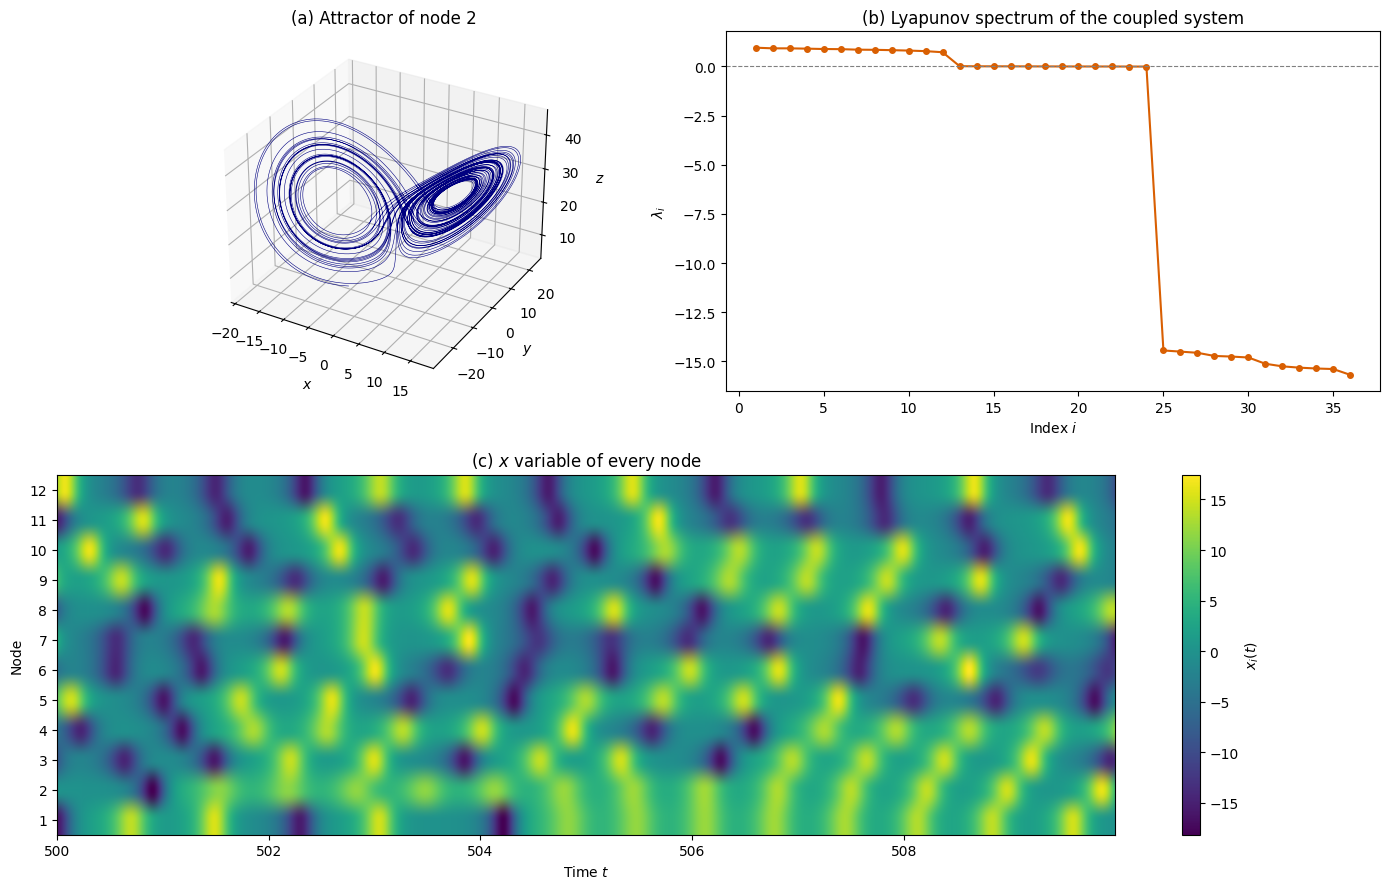

In [9]:
node = 1
fig = plt.figure(figsize=(14, 9))

ax1 = fig.add_subplot(2, 2, 1, projection="3d")
recent = slice(-50_000, None)  # the last 50 time units, so that the curve stays readable
ax1.plot(traj_fast[recent, node], traj_fast[recent, M + node], traj_fast[recent, 2 * M + node], color="navy", linewidth=0.4)
ax1.set_xlabel("$x$")
ax1.set_ylabel("$y$")
ax1.set_zlabel("$z$")
ax1.set_title(f"(a) Attractor of node {node + 1}")

ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(range(1, 3 * M + 1), spectrum_fast, "o-", color="#d95f02", markersize=4)
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax2.set_xlabel("Index $i$")
ax2.set_ylabel(r"$\lambda_i$")
ax2.set_title("(b) Lyapunov spectrum of the coupled system")

ax3 = fig.add_subplot(2, 1, 2)
last = slice(-10_000, None)  # the last 10 time units
image = ax3.imshow(traj_fast[last, :M].T, aspect="auto", cmap="viridis", origin="lower",
                   extent=[t_fast[last][0], t_fast[last][-1], 0.5, M + 0.5])
ax3.set_xlabel("Time $t$")
ax3.set_ylabel("Node")
ax3.set_yticks(range(1, M + 1))
ax3.set_title("(c) $x$ variable of every node")
fig.colorbar(image, ax=ax3, label="$x_i(t)$")
plt.tight_layout()
plt.show()

**Figure 4:** The 12 Lorenz systems coupled on the 12-node network with $K = 0.2$, integrated with the compiled RK4 solver and $h = 0.001$ for 500 time units. (a) The trajectory of node 2 in its $(x, y, z)$ space over the last 50 time units. (b) The 36 Lyapunov exponents of the coupled system in decreasing order, $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_{36}$; the dashed grey line marks zero. (c) The $x$ variable of every node, shown by the colour, over the last 10 time units.

Each node switches between the two wings of its own attractor (yellow and purple bands) at its
own times: with $K = 0.2$ the nodes are coupled, but far from synchronised. Whether the links
can be recovered from such data is the subject of the guides on
[correlation and mutual information](06_correlation_and_mutual_information.ipynb) and on
[MIR and APMSD](07_apmsd_network_inference.ipynb).

## Summary

- The Euler method follows the slope at the beginning of each step and has an error of order
  $h$; RK4 combines four slopes and has an error of order $h^4$. For the same step size, RK4 kept
  the conserved quantity of the Lotka-Volterra model many orders of magnitude better.
- The Lyapunov exponents of a system of ODEs are computed by integrating the variational
  equation together with the system. For the Lorenz system we found one positive, one zero and
  one negative exponent, whose sum is $-13.67$.
- RK45 chooses its own step size to keep the local error below a tolerance.
- The library offers four integrators with the same interface: `euler_with_lyapunov`,
  `rk4_with_lyapunov`, the compiled `build_rk4_lyapunov` (the fastest) and
  `solve_ivp_with_lyapunov` (adaptive).

## References

1. <a id="ref-1" name="ref-1"></a>H. Yıldırım, *Network Inference Using Information-theoretical Approaches, Statistical
   Hypothesis Tests, and The Amplitude-Phase Modulated Surrogate Data Method*, PhD thesis,
   University of Essex (2024), Chapter 3. <https://repository.essex.ac.uk/39296/>
2. <a id="ref-2" name="ref-2"></a>H. Yıldırım and C. G. Antonopoulos, Network inference using mutual information rate,
   statistical tests and amplitude-phase modulated surrogate data, *Chaos, Solitons & Fractals*
   188, 115554 (2024). <https://doi.org/10.1016/j.chaos.2024.115554>
3. <a id="ref-3" name="ref-3"></a>W. E. Boyce and R. C. DiPrima, *Elementary Differential Equations and Boundary Value
   Problems*, John Wiley & Sons (2012).
4. <a id="ref-4" name="ref-4"></a>G. Benettin, L. Galgani, A. Giorgilli and J.-M. Strelcyn, Lyapunov characteristic exponents
   for smooth dynamical systems and for Hamiltonian systems; a method for computing all of them.
   Part 1: Theory, *Meccanica* 15, 9–20 (1980).
5. <a id="ref-5" name="ref-5"></a>G. Benettin, L. Galgani, A. Giorgilli and J.-M. Strelcyn, Lyapunov characteristic exponents
   for smooth dynamical systems and for Hamiltonian systems; a method for computing all of them.
   Part 2: Numerical application, *Meccanica* 15, 21–30 (1980).
6. <a id="ref-6" name="ref-6"></a>K. T. Alligood, T. D. Sauer and J. A. Yorke, *Chaos: An Introduction to Dynamical Systems*,
   Springer (1996).
7. <a id="ref-7" name="ref-7"></a>J. Gleick, *Chaos: Making a New Science*, Penguin (2008).
8. <a id="ref-8" name="ref-8"></a>J. R. Dormand and P. J. Prince, A family of embedded Runge-Kutta formulae, *Journal of
   Computational and Applied Mathematics* 6, 19–26 (1980).

References 3 to 8 are the ones cited in Chapter 3 of the thesis [1].